# 11 · Municipios cercanos para la API (issue #16 · ML-04)

**Objetivo:** para cada uno de los 8.132 municipios, encontrar los más **cercanos en el mapa** y guardarlos en un fichero que usarán la API (Adriana), el front (Gema) y el RAG (Josema) para hablar de "municipios de la zona".

**Por qué geográfico:** el agua y los riesgos naturales (sequía, incendios, inundaciones) dependen del territorio. Un municipio comparte su agua y su clima con los que tiene al lado, no con uno parecido en población que está a 400 km.

**"Cercano" quiere decir próximo en el mapa** (distancia en línea recta entre los puntos `lat` y `lon` de cada municipio). No mide si se parecen en población, paro u otras características.

**Antes de ejecutar:** tener `data/processed/sitewise_ml/dataset_municipal_tasa_paro.csv` (notebook 08). El resultado se guarda en `data/reference/`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))  # por si no se ha hecho pip install -e .

from sitewise.ml.cercanos import N_CERCANOS, calcular_cercanos

ML = ROOT / 'data/processed/sitewise_ml'
REFERENCIA = ROOT / 'data/reference'
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
print('Raíz del proyecto:', ROOT)
print('Cercanos por municipio (N_CERCANOS):', N_CERCANOS)

Raíz del proyecto: d:\HELEN\PERSONAL\FORMACIÓN\0-ia_formacion\BOOTCAMP - F5\CURSO\PROYECTO_FINAL\SiteWise
Cercanos por municipio (N_CERCANOS): 5


## 1. Los datos

Cada municipio tiene un punto (`lat`, `lon`). Se comprueba que no falta ninguno y que los códigos INE son únicos.

In [2]:
datos = pd.read_csv(ML / 'dataset_municipal_tasa_paro.csv', dtype={'cod_ine': str})
assert datos['cod_ine'].is_unique
assert datos[['lat', 'lon']].notna().all().all()
print(datos.shape, '| lat de', datos['lat'].min().round(2), 'a', datos['lat'].max().round(2),
      '| lon de', datos['lon'].min().round(2), 'a', datos['lon'].max().round(2))

(8132, 125) | lat de 27.68 a 43.73 | lon de -18.01 a 4.29


## 2. Calcular los cercanos

`calcular_cercanos` busca, para cada municipio, los `N_CERCANOS` más próximos (distancia haversine, en km) sin contarse a sí mismo. Para devolver otra cantidad se cambia **solo** `N_CERCANOS` en `src/sitewise/ml/cercanos.py`.

In [3]:
cercanos = calcular_cercanos(datos['lat'], datos['lon'], datos['cod_ine'])
print(cercanos.shape, '=', datos.shape[0], 'municipios ×', N_CERCANOS)
print('Distancia por posición (km):')
print(cercanos.groupby('posicion')['distancia_km'].describe()[['mean', '50%', 'max']].round(1).to_string())

(40660, 4) = 8132 municipios × 5
Distancia por posición (km):
          mean  50%    max
posicion                  
1          5.2  4.6  162.9
2          6.4  5.8  163.7
3          7.6  6.8  164.5
4          8.6  7.7  165.3
5          9.5  8.5  165.3


## 3. Ejemplos

San Fernando y Cádiz (los dos de la bahía), Toledo, Madrid y un pueblo pequeño.

In [4]:
info = datos.set_index('cod_ine')[['nombre', 'provincia']]


def ver(cod):
    t = cercanos[cercanos['cod_ine'] == cod].copy()
    t['nombre'] = t['cod_ine_cercano'].map(info['nombre'])
    t['provincia'] = t['cod_ine_cercano'].map(info['provincia'])
    print(f"{info.loc[cod, 'nombre']} ({info.loc[cod, 'provincia']})")
    print(t[['posicion', 'nombre', 'provincia', 'distancia_km']].round(1).to_string(index=False))
    print()


for cod in ['11031', '11012', '45168', '28079', '01001']:
    if cod in info.index:
        ver(cod)

San Fernando (Cádiz)
 posicion                    nombre provincia  distancia_km
        1                     Cádiz     Cádiz           7.6
        2   Chiclana de la Frontera     Cádiz           9.5
        3               Puerto Real     Cádiz          12.1
        4      Conil de la Frontera     Cádiz          20.1
        5 Puerto de Santa María, El     Cádiz          20.1

Cádiz (Cádiz)
 posicion                    nombre provincia  distancia_km
        1              San Fernando     Cádiz           7.6
        2               Puerto Real     Cádiz          14.2
        3 Puerto de Santa María, El     Cádiz          15.2
        4   Chiclana de la Frontera     Cádiz          17.0
        5                      Rota     Cádiz          21.6

Toledo (Toledo)
 posicion               nombre provincia  distancia_km
        1        Olías del Rey    Toledo           8.7
        2               Cobisa    Toledo           9.1
        3              Mocejón    Toledo           9.6
       

## 4. ¿Cómo de cerca y de lejos?

Dos comprobaciones:

1. Qué parte de los cercanos son de la misma provincia y comunidad.
2. Qué municipios tienen los cercanos más lejos. Son sobre todo islas y ciudades autónomas, donde el "cercano" puede estar al otro lado del mar. Por eso se guarda `distancia_km`: la API puede usarla para avisar.

In [5]:
c = cercanos.copy()
for col in ['provincia', 'ccaa']:
    mapa = datos.set_index('cod_ine')[col]
    c['igual_' + col] = c['cod_ine'].map(mapa).to_numpy() == c['cod_ine_cercano'].map(mapa).to_numpy()
print(f"Cercanos de la misma provincia: {c['igual_provincia'].mean():.1%}")
print(f"Cercanos de la misma comunidad: {c['igual_ccaa'].mean():.1%}")

media = cercanos.groupby('cod_ine')['distancia_km'].mean().rename('distancia_media_km')
print()
print('Distancia media a sus cercanos (km), todos los municipios:')
print(media.describe().round(1).to_string())
lejanos = media.sort_values(ascending=False).head(10).to_frame()
lejanos['nombre'] = lejanos.index.map(info['nombre'])
lejanos['provincia'] = lejanos.index.map(info['provincia'])
print()
print('Los 10 municipios con los cercanos más lejanos:')
print(lejanos.round(1).to_string())
print()
print('Municipios con una distancia media de más de 50 km:', int((media > 50).sum()))

Cercanos de la misma provincia: 92.0%
Cercanos de la misma comunidad: 96.6%

Distancia media a sus cercanos (km), todos los municipios:
count    8132.0
mean        7.5
std         3.8
min         1.5
25%         5.2
50%         6.7
75%         8.9
max       164.3

Los 10 municipios con los cercanos más lejanos:
         distancia_media_km                  nombre                   provincia
cod_ine                                                                        
52001                 164.3                 Melilla  Ciudad Autónoma de Melilla
38901                  55.4  Pinar de El Hierro, El      Santa Cruz de Tenerife
38013                  51.8                Frontera      Santa Cruz de Tenerife
38048                  49.0                Valverde      Santa Cruz de Tenerife
51001                  37.6                   Ceuta    Ciudad Autónoma de Ceuta
35014                  32.2               Oliva, La                  Las Palmas
35015                  31.2                  Pá

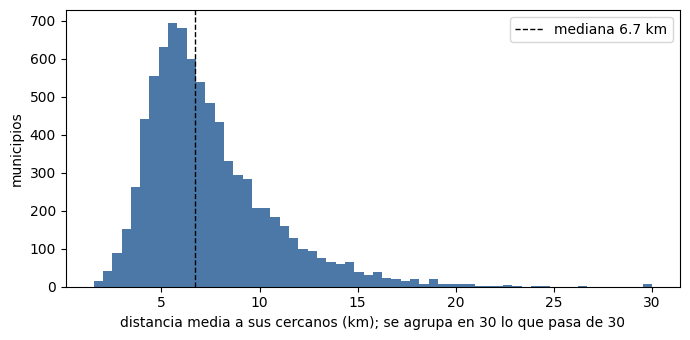

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(media.clip(upper=30), bins=60, color='#4c78a8')
ax.axvline(media.median(), color='black', ls='--', lw=1, label=f'mediana {media.median():.1f} km')
ax.set_xlabel('distancia media a sus cercanos (km); se agrupa en 30 lo que pasa de 30')
ax.set_ylabel('municipios')
ax.legend()
plt.tight_layout()
plt.show()

## 5. ¿De verdad comparten agua y riesgos?

Para cada variable de agua y de riesgo se compara el valor de cada municipio con la **media de sus cercanos**, con la correlación de Spearman (1 = se parecen del todo, 0 = nada). Como referencia, se hace lo mismo con 5 municipios **elegidos al azar**: ahí tiene que salir cerca de 0.

Ojo con la lectura:
- Se usan solo los municipios con valor. En `eventos_cnih_2000_2023_n` y en los dos de incendios faltan muchos valores y no se sabe si falta el dato o simplemente no hubo eventos.
- Se usa el agua original (`agua_subterranea_mal_estado_cuantitativo_pct`), no `agua_vecinos_pct`, porque esta última ya está rellenada con los vecinos y saldría parecida por construcción.
- Algunas variables vienen de fuentes por zonas amplias, y entonces los vecinos repiten el mismo valor casi por definición. Es una comprobación de que el criterio geográfico tiene sentido, no una medida precisa de riesgo.

In [7]:
VARIABLES = {
    'agua_subterranea_mal_estado_cuantitativo_pct': 'Acuíferos en mal estado (cantidad)',
    'agua_subterranea_mal_estado_quimico_pct': 'Acuíferos en mal estado (química)',
    'estres_hidrico_pct': 'Estrés hídrico',
    'eventos_cnih_2000_2023_n': 'Eventos CNIH 2000-2023',
    'siniestros_forestales_100km2_2006_2015': 'Siniestros forestales por 100 km²',
    'ha_afectadas_100km2_2006_2015': 'Hectáreas afectadas por 100 km²',
}
por_cod = datos.set_index('cod_ine')
rng = np.random.default_rng(0)
azar = rng.integers(0, len(datos), size=(len(datos), N_CERCANOS))

filas = []
for col, etiqueta in VARIABLES.items():
    v = por_cod[col]
    media_cercanos = cercanos['cod_ine_cercano'].map(v).groupby(cercanos['cod_ine']).mean()
    media_azar = pd.Series(pd.DataFrame(v.to_numpy(float)[azar]).mean(axis=1).to_numpy(), index=v.index)
    t = pd.DataFrame({'propio': v, 'cercanos': media_cercanos, 'azar': media_azar}).dropna()
    filas.append({
        'variable': etiqueta,
        'municipios con valor': len(t),
        'corr. con cercanos': t['propio'].corr(t['cercanos'], method='spearman'),
        'corr. con azar': t['propio'].corr(t['azar'], method='spearman'),
    })
print(pd.DataFrame(filas).round(2).to_string(index=False))

                          variable  municipios con valor  corr. con cercanos  corr. con azar
Acuíferos en mal estado (cantidad)                  7408                0.88            0.01
 Acuíferos en mal estado (química)                  7408                0.92            0.00
                    Estrés hídrico                  8108                0.97            0.01
            Eventos CNIH 2000-2023                  1933                0.52           -0.06
 Siniestros forestales por 100 km²                  4091                0.74            0.00
   Hectáreas afectadas por 100 km²                  4091                0.55            0.03


## 6. Guardar el fichero

Formato largo (una fila por municipio y cercano), ordenado por `cod_ine` y `posicion`, con `cod_ine` como texto. Se guarda con saltos de línea `\n` para que el fichero no cambie según el sistema operativo.

In [8]:
REFERENCIA.mkdir(parents=True, exist_ok=True)
destino = REFERENCIA / 'municipios_cercanos_v01.csv'
cercanos.to_csv(destino, index=False, encoding='utf-8', lineterminator='\n')

leido = pd.read_csv(destino, dtype={'cod_ine': str, 'cod_ine_cercano': str})
assert len(leido) == len(datos) * N_CERCANOS
assert leido['cod_ine'].nunique() == len(datos)
assert (leido['cod_ine'] != leido['cod_ine_cercano']).all()
print('Guardado en', destino.parent)
print(leido.head(6).to_string(index=False))

Guardado en d:\HELEN\PERSONAL\FORMACIÓN\0-ia_formacion\BOOTCAMP - F5\CURSO\PROYECTO_FINAL\SiteWise\data\reference
cod_ine cod_ine_cercano  posicion  distancia_km
  01001           01021         1         3.397
  01001           01027         2         9.259
  01001           01037         3        10.522
  01001           01059         4        11.338
  01001           01016         5        11.753
  01002           48075         1         7.527


## Conclusiones

- Cada municipio tiene sus `N_CERCANOS` (5) más cercanos, y `posicion` 1 es el más cercano. San Fernando sale con Cádiz, Chiclana y Puerto Real.
- **Cercano = próximo en el mapa**, no parecido en características. Es el criterio adecuado para agua y riesgos naturales, que dependen del territorio.
- Casi todos los cercanos son de la misma provincia (92 %) y la distancia habitual es de unos 5 a 10 km.
- **Los más lejanos son islas y ciudades autónomas** (Melilla, Canarias, Formentera, Ceuta). La API puede usar `distancia_km` para avisar o no mostrar los cercanos cuando estén lejos; el umbral lo decide el equipo.
- Los cercanos comparten mucho el agua y el estrés hídrico, y bastante menos las inundaciones y los incendios. Con municipios al azar la correlación es casi 0.
- La distancia es en línea recta entre dos puntos por municipio. **No tiene en cuenta relieve, costa ni cuencas:** dos municipios cercanos pueden estar en cuencas distintas, y en municipios muy extensos la distancia entre puntos no es la distancia entre sus límites.
- Si cambian los municipios o sus coordenadas, hay que regenerar este fichero y subir la versión del nombre (`_v02`).